# TP4 – Analyse des ventes et graphiques (UC-08)

IPSSI · Mastère Data & IA · Ryma Dinari · 19/11/2026 · projet fait seule

**Ce que fait ce notebook** : je reprends les données propres du TP3. Je calcule des indicateurs (chiffre d'affaires,
nombre de tickets, panier moyen…), je fais des statistiques, je réponds à deux questions métier (plus une en bonus)
et je fais des graphiques avec un commentaire.

**Comment** : les gros calculs sont faits par **Spark** (PySpark). Ensuite, seuls les petits tableaux de résultats
(quelques dizaines de lignes) passent dans **Pandas**, puis dans **Matplotlib** pour dessiner les graphiques.

| # | Partie | Étape du TP |
|---|---|---|
| 1 | Préparer l'environnement et démarrer Spark | §1.2 à §1.5 |
| 2 | Charger et vérifier les données | Étape 1 |
| 3 | Calculer les indicateurs (KPI) | Étape 2 |
| 4 | Statistiques | Étape 3 |
| 5 | Analyse 1 – le chiffre d'affaires dans le temps (Q1) + graphique | Étapes 4 et 5 |
| 6 | Analyse 2 – comparer les magasins (Q5) + graphique | Étapes 4 et 5 |
| 7 | Analyse 3 (bonus) – les catégories (Q3) + graphique | Étapes 4 et 5 |
| 8 | Répartition des montants des tickets (histogramme) | Étape 5 |
| 9 | Conclusions, limites et conseils | Étape 6 |

## 1. Préparer l'environnement et démarrer Spark

Je reprends l'environnement Python du TP3 (`~/TP3/.venv`). J'ai juste ajouté Pandas et Matplotlib. La cellule ci-dessous affiche les versions des outils (preuve pour le README).

In [1]:
import sys, platform, warnings
from pathlib import Path

# Spark affiche un message avec Pandas 3 : pas grave pour nos petits tableaux, on le cache
warnings.filterwarnings("ignore", category=FutureWarning)

# config.py est dans le même dossier que le notebook
sys.path.insert(0, str(Path.cwd().resolve()))
from config import *

import pyspark, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

print("Python     :", platform.python_version())
print("PySpark    :", pyspark.__version__)
print("Pandas     :", pd.__version__)
print("Matplotlib :", matplotlib.__version__)
print("Silver     :", SILVER)
print("Gold       :", GOLD)

OUTPUTS.mkdir(parents=True, exist_ok=True)
VISUALISATIONS.mkdir(parents=True, exist_ok=True)

Python     : 3.12.3
PySpark    : 4.3.0
Pandas     : 3.1.1
Matplotlib : 3.11.2
Silver     : /home/rymadinari/TP3/data/silver
Gold       : /home/rymadinari/TP3/data/gold


In [2]:
spark = creer_session()
print("Version Spark :", spark.version, "| master :", spark.sparkContext.master)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/19 14:35:46 WARN Utils: Your hostname, rymadinari-VivoBook-ASUSLaptop-M1702QA-M1702QA, resolves to a loopback address: 127.0.1.1; using 10.188.47.136 instead (on interface wlp1s0)
26/11/19 14:35:46 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/19 14:35:47 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Version Spark : 4.3.0 | master : local[*]


## 2. Charger et vérifier les données (étape 1)

Je charge 2 fichiers Gold (données déjà regroupées) et 3 fichiers Silver (données nettoyées), tous faits au TP3.
Pour chacun, j'affiche ses colonnes et son nombre de lignes, et je vérifie ce que représente une ligne.
Plus de détails dans `docs/business-analysis.md (partie 0)`.

In [3]:
sales      = spark.read.parquet(str(SILVER / "sales"))
stores     = spark.read.parquet(str(SILVER / "stores"))
dates      = spark.read.parquet(str(SILVER / "dates"))
gold_mois  = spark.read.parquet(str(GOLD / "ventes_magasin_mois"))
gold_cat   = spark.read.parquet(str(GOLD / "ventes_categorie_annee"))

jeux = {
    "silver/sales": sales, "silver/stores": stores, "silver/dates": dates,
    "gold/ventes_magasin_mois": gold_mois, "gold/ventes_categorie_annee": gold_cat,
}
for nom, df in jeux.items():
    print(f"{nom:30s} {df.count():>9,d} lignes  {len(df.columns):>3d} colonnes".replace(",", " "))

silver/sales                     667 579 lignes   25 colonnes
silver/stores                         12 lignes   30 colonnes
silver/dates                     109 573 lignes   29 colonnes
gold/ventes_magasin_mois             720 lignes   11 colonnes
gold/ventes_categorie_annee           45 lignes    6 colonnes


In [4]:
gold_mois.printSchema()
gold_mois.orderBy("annee", "mois", "s_store_sk").show(5)

root
 |-- s_store_sk: long (nullable = true)
 |-- s_store_name: string (nullable = true)
 |-- s_state: string (nullable = true)
 |-- annee: integer (nullable = true)
 |-- mois: integer (nullable = true)
 |-- ca: decimal(17,2) (nullable = true)
 |-- quantite: long (nullable = true)
 |-- nb_tickets: long (nullable = true)
 |-- nb_lignes: long (nullable = true)
 |-- marge: decimal(17,2) (nullable = true)
 |-- panier_moyen: decimal(18,2) (nullable = true)

+----------+------------+-------+-----+----+----------+--------+----------+---------+----------+------------+
|s_store_sk|s_store_name|s_state|annee|mois|        ca|quantite|nb_tickets|nb_lignes|     marge|panier_moyen|
+----------+------------+-------+-----+----+----------+--------+----------+---------+----------+------------+
|         0|      Forest|     CO| 2001|   1|1386332.96|   44609|       111|      861|-846846.06|    12489.49|
|         1|    Hillside|     TN| 2001|   1|1564162.75|   47121|       129|      932|-754801.44|    121

In [5]:
gold_cat.printSchema()
gold_cat.orderBy("annee", F.desc("ca")).show(5)

root
 |-- categorie: string (nullable = true)
 |-- annee: integer (nullable = true)
 |-- ca: decimal(17,2) (nullable = true)
 |-- quantite: long (nullable = true)
 |-- nb_lignes: long (nullable = true)
 |-- part_ca_pct: decimal(24,2) (nullable = true)

+--------------------+-----+------------+--------+---------+-----------+
|           categorie|annee|          ca|quantite|nb_lignes|part_ca_pct|
+--------------------+-----+------------+--------+---------+-----------+
|               Music| 2001|105338495.32| 3086125|    60993|      45.31|
|               Books| 2001| 62231425.35| 1819416|    35948|      26.77|
|         Movies & TV| 2001| 15129909.71|  445598|     8783|       6.51|
|Clothing & Access...| 2001| 11434730.37|  325858|     6463|       4.92|
|         Electronics| 2001| 11108757.83|  327226|     6519|       4.78|
+--------------------+-----+------------+--------+---------+-----------+
only showing top 5 rows


In [6]:
# Les colonnes de silver/sales dont j'ai besoin
sales.select("ss_sold_date_sk", "ss_store_sk", "ss_ticket_number", "ss_item_sk",
             "ss_quantity", "ss_sales_price", "ss_net_paid", "ss_net_profit").printSchema()

root
 |-- ss_sold_date_sk: long (nullable = true)
 |-- ss_store_sk: long (nullable = true)
 |-- ss_ticket_number: long (nullable = true)
 |-- ss_item_sk: long (nullable = true)
 |-- ss_quantity: integer (nullable = true)
 |-- ss_sales_price: decimal(7,2) (nullable = true)
 |-- ss_net_paid: decimal(7,2) (nullable = true)
 |-- ss_net_profit: decimal(7,2) (nullable = true)



**Que représente une ligne ?** (on appelle ça la **granularité**). Je vérifie qu'il n'y a pas de doublon, sinon les totaux seraient faux.

- `gold/ventes_magasin_mois` : une ligne = un magasin pour un mois ;
- `gold/ventes_categorie_annee` : une ligne = une catégorie pour une année ;
- `silver/sales` : une ligne = **un produit dans un ticket** (pas un ticket entier). Un ticket a plusieurs lignes.

In [7]:
def doublons(df, cles):
    return df.groupBy(*cles).count().filter("count > 1").count()

print("Doublons (magasin, année, mois) dans gold_mois :", doublons(gold_mois, ["s_store_sk", "annee", "mois"]))
print("Doublons (catégorie, année) dans gold_cat      :", doublons(gold_cat, ["categorie", "annee"]))

nb_lignes  = sales.count()
nb_tickets = sales.select(F.countDistinct("ss_ticket_number")).first()[0]
print(f"silver/sales : {nb_lignes} lignes pour {nb_tickets} tickets distincts "
      f"-> {nb_lignes / nb_tickets:.1f} lignes par ticket en moyenne")

# Un ticket est-il toujours dans un seul magasin ? (il le faut pour compter les tickets par magasin)
tickets_multi_magasins = (sales.groupBy("ss_ticket_number")
                          .agg(F.countDistinct("ss_store_sk").alias("n")).filter("n > 1").count())
print("Tickets présents dans plusieurs magasins :", tickets_multi_magasins)

Doublons (magasin, année, mois) dans gold_mois : 0
Doublons (catégorie, année) dans gold_cat      : 0
silver/sales : 667579 lignes pour 89100 tickets distincts -> 7.5 lignes par ticket en moyenne
Tickets présents dans plusieurs magasins : 0


**Vérification** : le chiffre d'affaires total doit être le même dans le Silver et dans le Gold.
Je l'avais déjà vérifié au TP3, je le refais ici avant de commencer.

In [8]:
ca_silver = sales.agg(F.sum("ss_net_paid")).first()[0]
ca_gold_mois = gold_mois.agg(F.sum("ca")).first()[0]
ca_gold_cat = gold_cat.agg(F.sum("ca")).first()[0]
print("CA Silver                 :", ca_silver)
print("CA gold/ventes_magasin_mois :", ca_gold_mois)
print("CA gold/ventes_categorie_annee :", ca_gold_cat)
assert ca_silver == ca_gold_mois == ca_gold_cat, "Incohérence entre Silver et Gold"
print("OK : les trois totaux sont identiques")

periode = (sales.join(dates, sales.ss_sold_date_sk == dates.d_date_sk)
           .agg(F.min("d_date").alias("premiere_vente"), F.max("d_date").alias("derniere_vente")))
periode.show()

CA Silver                 : 1150529586.37
CA gold/ventes_magasin_mois : 1150529586.37
CA gold/ventes_categorie_annee : 1150529586.37
OK : les trois totaux sont identiques
+--------------+--------------+
|premiere_vente|derniere_vente|
+--------------+--------------+
|    2001-01-01|    2005-12-13|
+--------------+--------------+



## 3. Calculer les indicateurs (étape 2)

Je reprends la liste des indicateurs du TP1 (K1 à K13). Je garde seulement ceux qu'on peut calculer **et** qui ont du sens
avec mes données (ventes en magasin seulement) :

| Code | Indicateur | Calcul | Colonnes | Une valeur pour |
|---|---|---|---|---|
| K1 | Chiffre d'affaires | somme de `ss_net_paid` | `ss_net_paid` | tout, ou par magasin / mois / catégorie |
| K2 | Nombre de tickets | nombre de numéros de ticket **différents** | `ss_ticket_number` | tout, ou par magasin |
| K3 | Panier moyen | K1 ÷ K2 | K1, K2 | tout, ou par magasin |
| K4 | Quantité vendue | somme de `ss_quantity` | `ss_quantity` | tout |
| K7 | Évolution du chiffre d'affaires | (année − année d'avant) ÷ année d'avant, sur la même période | K1, dates | année |
| K11 | Chiffre d'affaires par employé | CA du magasin ÷ nombre d'employés | K1, `s_number_employees` | magasin |

Ceux que je laisse de côté : la marge (K6), car 74 % des ventes sont à perte, ce n'est pas réaliste ;
K5, K8, K9, K10, K12, car leurs tables n'ont pas été nettoyées au TP3 ; K13, car il n'y a pas de coûts dans les données.
Tout est expliqué dans `docs/kpi-dictionary.md`.

In [9]:
kpi_global = sales.agg(
    F.sum("ss_net_paid").alias("K1_ca_net"),
    F.countDistinct("ss_ticket_number").alias("K2_nb_transactions"),
    F.sum("ss_quantity").alias("K4_quantites"),
    F.count("*").alias("nb_lignes_de_vente"),
).withColumn("K3_panier_moyen", F.round(F.col("K1_ca_net") / F.col("K2_nb_transactions"), 2))
kpi_global.show(truncate=False)

+-------------+------------------+------------+------------------+---------------+
|K1_ca_net    |K2_nb_transactions|K4_quantites|nb_lignes_de_vente|K3_panier_moyen|
+-------------+------------------+------------+------------------+---------------+
|1150529586.37|89100             |33755474    |667579            |12912.79       |
+-------------+------------------+------------+------------------+---------------+



**K7 – Évolution du chiffre d'affaires.** 2005 s'arrête le 13 décembre. Pour comparer ce qui est comparable,
je compare aussi chaque année **sur la même période** : du 1er janvier au 13 décembre.

In [10]:
ventes_dates = sales.join(dates, sales.ss_sold_date_sk == dates.d_date_sk)

ca_annuel = (ventes_dates
    .groupBy(F.col("d_year").alias("annee"))
    .agg(F.sum("ss_net_paid").alias("ca_annee_complete"),
         F.sum(F.when((F.col("d_moy") < 12) | (F.col("d_dom") <= 13), F.col("ss_net_paid")))
          .alias("ca_01jan_13dec"))
    .orderBy("annee"))

from pyspark.sql import Window
w = Window.orderBy("annee")
ca_annuel = (ca_annuel
    .withColumn("K7_evol_annee_pct",
                F.round((F.col("ca_annee_complete") / F.lag("ca_annee_complete").over(w) - 1) * 100, 2))
    .withColumn("K7_evol_01jan_13dec_pct",
                F.round((F.col("ca_01jan_13dec") / F.lag("ca_01jan_13dec").over(w) - 1) * 100, 2)))
pdf_annuel = ca_annuel.toPandas()   # 5 lignes
pdf_annuel

,annee,ca_annee_complete,ca_01jan_13dec,K7_evol_annee_pct,K7_evol_01jan_13dec_pct
0,2001,232498659.83,221384812.28,None,None
1,2002,230947265.82,219729044.56,-0.67,-0.75
2,2003,233575185.63,222170893.13,1.14,1.11
3,2004,234344934.29,222565329.77,0.33,0.18
4,2005,219163540.80,219163540.80,-6.48,-1.53


Attention à la ligne 2005 « année complète » (−6,5 %) : elle est **trompeuse**, il manque 18 jours. Sur la même période (1er janvier au 13 décembre), la baisse n'est que de −1,5 %, comme les autres années (entre −0,8 % et +1,1 %).

In [11]:
# K1, K2, K3, K11 par magasin (sur toute la période 2001-01-01 -> 2005-12-13)
kpi_magasin = (sales
    .groupBy("ss_store_sk")
    .agg(F.sum("ss_net_paid").alias("K1_ca_net"),
         F.countDistinct("ss_ticket_number").alias("K2_nb_transactions"),
         F.sum("ss_quantity").alias("K4_quantites"))
    .join(stores.select(F.col("s_store_sk").alias("ss_store_sk"), "s_store_name", "s_state",
                        "s_number_employees"), "ss_store_sk")
    .withColumn("K3_panier_moyen", F.round(F.col("K1_ca_net") / F.col("K2_nb_transactions"), 2))
    .withColumn("K11_ca_par_employe", F.round(F.col("K1_ca_net") / F.col("s_number_employees"), 2))
    .orderBy(F.desc("K1_ca_net")))
pdf_magasins = kpi_magasin.toPandas()   # 12 lignes
pdf_magasins

,ss_store_sk,K1_ca_net,K2_nb_transactions,K4_quantites,s_store_name,s_state,s_number_employees,K3_panier_moyen,K11_ca_par_employe
0,7,98950137.76,7645,2915053,Buffalo,KS,225,12943.12,439778.39
1,4,96770105.59,7462,2832572,Elmwood,KY,254,12968.39,380984.67
2,9,96748356.68,7435,2830684,Germantown,WV,213,13012.56,454217.64
3,0,96727851.94,7456,2830581,Forest,CO,217,12973.16,445750.47
4,8,96578622.89,7414,2821869,Williamstown,TX,298,13026.52,324089.34
5,3,96063990.59,7396,2800824,Pioneer,TX,221,12988.64,434678.69
6,1,95929844.66,7422,2817524,Hillside,TN,244,12925.07,393155.10
7,11,95607843.48,7449,2790631,Bedford,KY,221,12834.99,432614.68
8,6,94751173.08,7284,2780253,Bloomfield,IN,225,13008.12,421116.32
9,10,94263977.55,7409,2785773,Avalon,TN,254,12722.90,371118.02


In [12]:
# J'enregistre les indicateurs dans un fichier CSV (un indicateur par ligne)
g = kpi_global.first().asDict()
lignes = [
    ("K1", "Chiffre d'affaires net", float(g["K1_ca_net"]), "unité monétaire (devise non précisée)", "ventes magasin 2001-01-01 -> 2005-12-13"),
    ("K2", "Nombre de transactions", g["K2_nb_transactions"], "tickets", "idem"),
    ("K3", "Panier moyen", float(g["K3_panier_moyen"]), "unité monétaire par ticket", "idem"),
    ("K4", "Quantités vendues", g["K4_quantites"], "unités", "idem"),
]
for _, r in pdf_annuel.iterrows():
    if pd.notna(r["K7_evol_01jan_13dec_pct"]):
        lignes.append(("K7", f"Évolution du CA {int(r['annee'])} vs {int(r['annee'])-1} (01/01-13/12)",
                       float(r["K7_evol_01jan_13dec_pct"]), "%", "période identique"))
lignes.append(("K11", "CA par employé (moyenne des 12 magasins)",
               round(float(pdf_magasins["K11_ca_par_employe"].astype(float).mean()), 2),
               "unité monétaire par employé", "sur 5 ans"))
pdf_kpi = pd.DataFrame(lignes, columns=["code", "kpi", "valeur", "unite", "perimetre"])
pdf_kpi.to_csv(OUTPUTS / "kpi.csv", index=False)
pdf_magasins.to_csv(OUTPUTS / "kpi_par_magasin.csv", index=False)
pdf_annuel.to_csv(OUTPUTS / "ca_annuel.csv", index=False)
pdf_kpi

,code,kpi,valeur,unite,perimetre
0,K1,Chiffre d'affaires net,1.150530e+09,unité monétaire (devise non précisée),ventes magasin 2001-01-01 -> 2005-12-13
1,K2,Nombre de transactions,8.910000e+04,tickets,idem
2,K3,Panier moyen,1.291279e+04,unité monétaire par ticket,idem
3,K4,Quantités vendues,3.375547e+07,unités,idem
4,K7,Évolution du CA 2002 vs 2001 (01/01-13/12),-7.500000e-01,%,période identique
5,K7,Évolution du CA 2003 vs 2002 (01/01-13/12),1.110000e+00,%,période identique
6,K7,Évolution du CA 2004 vs 2003 (01/01-13/12),1.800000e-01,%,période identique
7,K7,Évolution du CA 2005 vs 2004 (01/01-13/12),-1.530000e+00,%,période identique
8,K11,CA par employé (moyenne des 12 magasins),4.073917e+05,unité monétaire par employé,sur 5 ans


## 4. Statistiques (étape 3)

Je regarde les chiffres de **deux façons**, car ils ne disent pas la même chose :

1. **par ligne** (`silver/sales`, 667 579 lignes) : quantité, prix d'un article, montant payé ;
2. **par ticket** (89 100 tickets) : montant du ticket, nombre de produits. Je fabrique d'abord ce tableau avec Spark (je regroupe par numéro de ticket).

Rappel : la **médiane** est la valeur du milieu (la moitié est en dessous). Spark la calcule de façon approchée (`percentile_approx`), c'est assez précis ici.
L'**écart-type** dit si les valeurs sont proches de la moyenne (petit) ou très étalées (grand).

In [13]:
def stats(df, colonnes, granularite):
    exprs = []
    for c in colonnes:
        exprs += [F.count(c).alias(f"{c}|nb"), F.min(c).alias(f"{c}|min"), F.max(c).alias(f"{c}|max"),
                  F.round(F.avg(c), 2).alias(f"{c}|moyenne"),
                  F.percentile_approx(c, 0.5).alias(f"{c}|mediane"),
                  F.round(F.stddev(c), 2).alias(f"{c}|ecart_type"),
                  F.sum(c).alias(f"{c}|somme")]
    r = df.agg(*exprs).first().asDict()
    out = []
    for c in colonnes:
        out.append({"granularite": granularite, "variable": c,
                    **{k: r[f"{c}|{k}"] for k in ["nb", "min", "max", "moyenne", "mediane", "ecart_type", "somme"]}})
    return pd.DataFrame(out)

tickets = (sales.groupBy("ss_ticket_number")
           .agg(F.sum("ss_net_paid").alias("montant_ticket"),
                F.count("*").alias("nb_lignes_ticket"),
                F.sum("ss_quantity").alias("quantite_ticket")))

pdf_stats = pd.concat([
    stats(sales, ["ss_quantity", "ss_sales_price", "ss_net_paid"], "ligne de ticket"),
    stats(tickets, ["montant_ticket", "nb_lignes_ticket", "quantite_ticket"], "ticket"),
], ignore_index=True)

# Additionner des prix d'articles n'a pas de sens : je vide cette case
pdf_stats.loc[pdf_stats["variable"] == "ss_sales_price", "somme"] = None
pdf_stats.to_csv(OUTPUTS / "statistiques.csv", index=False)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", " "))
pdf_stats

,granularite,variable,nb,min,max,moyenne,mediane,ecart_type,somme
0,ligne de ticket,ss_quantity,667579,1,100,50.56,51,28.88,33755474
1,ligne de ticket,ss_sales_price,667579,0.00,199.30,37.86,27.69,34.40,None
2,ligne de ticket,ss_net_paid,667579,0.00,18745.00,1723.44,878.41,2 167.90,1150529586.37
3,ticket,montant_ticket,89100,0.00,64785.95,12912.79,11640.86,9 063.74,1150529586.37
4,ticket,nb_lignes_ticket,89100,1,14,7.49,7,4.02,667579
5,ticket,quantite_ticket,89100,1,1143,378.85,372,217.36,33755474


In [14]:
# Nombre de lignes, de tickets et chiffre d'affaires par année
pdf_rep_annee = (ventes_dates.groupBy(F.col("d_year").alias("annee"))
    .agg(F.count("*").alias("nb_lignes"), F.countDistinct("ss_ticket_number").alias("nb_tickets"),
         F.sum("ss_net_paid").alias("ca"))
    .orderBy("annee").toPandas())
pdf_rep_annee

,annee,nb_lignes,nb_tickets,ca
0,2001,134873,17991,232498659.83
1,2002,135084,17990,230947265.82
2,2003,134773,17990,233575185.63
3,2004,136014,18039,234344934.29
4,2005,126835,17090,219163540.80


**Ce que je remarque** :
- une ligne vaut 1 723 en moyenne et un ticket 12 913. Le **panier moyen est très élevé** parce qu'un ticket contient 7,5 produits, et chaque produit est acheté environ 50 fois (quantité entre 1 et 100). Ça fait environ 379 articles par ticket ;
- pour le montant d'une ligne, la moyenne (1 723) est le double de la médiane (878) : quelques lignes très chères (jusqu'à 18 745) tirent la moyenne vers le haut. Le minimum est 0 (des ventes à 0 € déjà vues au TP3) ;
- il y a presque le même nombre de tickets chaque année (environ 18 000) : c'est le programme qui a inventé les données qui fait ça, pas de vrais clients.

## 5. Analyse 1 – Comment évolue le chiffre d'affaires d'un mois à l'autre ? (Q1)

| | |
|---|---|
| **Question** | Le chiffre d'affaires monte-t-il ou baisse-t-il, d'un mois et d'une année à l'autre ? (Q1 du TP1) |
| **Qui la pose** | La direction, pour fixer les objectifs de l'année |
| **Données** | `gold/ventes_magasin_mois` (720 lignes = 12 magasins × 60 mois) |
| **Méthode** | J'additionne les 12 magasins pour chaque mois. Puis je calcule une **moyenne mobile sur 12 mois** (pour chaque mois, la moyenne des 12 derniers mois), qui lisse la courbe. |
| **Point d'attention** | Décembre 2005 n'a que 13 jours : je l'affiche à part, sans le relier à la courbe |

In [15]:
ventes_par_mois = (gold_mois
    .groupBy("annee", "mois")
    .agg(F.sum("ca").alias("ca"), F.sum("nb_tickets").alias("nb_tickets"))
    .withColumn("mois_txt", F.format_string("%d-%02d", "annee", "mois"))
    .orderBy("annee", "mois"))
pdf_mois = ventes_par_mois.toPandas()          # 60 lignes
pdf_mois["ca"] = pdf_mois["ca"].astype(float)
pdf_mois["partiel"] = (pdf_mois["annee"] == 2005) & (pdf_mois["mois"] == 12)
complet = pdf_mois[~pdf_mois["partiel"]].copy()
complet["moyenne_mobile_12m"] = complet["ca"].rolling(12).mean()
pdf_mois = pdf_mois.merge(complet[["mois_txt", "moyenne_mobile_12m"]], on="mois_txt", how="left")
pdf_mois.to_csv(OUTPUTS / "ventes_par_mois.csv", index=False)

print(f"{len(pdf_mois)} mois ; CA mensuel moyen (hors déc. 2005) : {complet['ca'].mean()/1e6:.2f} M")
print("Mois le plus haut :", complet.loc[complet['ca'].idxmax(), 'mois_txt'], f"{complet['ca'].max()/1e6:.2f} M")
print("Mois le plus bas  :", complet.loc[complet['ca'].idxmin(), 'mois_txt'], f"{complet['ca'].min()/1e6:.2f} M")
print(f"Écart-type / moyenne : {complet['ca'].std() / complet['ca'].mean() * 100:.1f} %")

60 mois ; CA mensuel moyen (hors déc. 2005) : 19.36 M
Mois le plus haut : 2003-10 20.63 M
Mois le plus bas  : 2002-02 17.59 M
Écart-type / moyenne : 3.2 %


In [16]:
# Chiffre d'affaires moyen de chaque mois (janvier, février…) sur 2001-2004, pour voir s'il y a des saisons
pdf_saison = (complet[complet["annee"] <= 2004].groupby("mois")["ca"].mean() / 1e6).round(2)
pdf_saison.to_frame("ca_moyen_M").T

mois,1,2,3,4,5,6,7,8,9,10,11,12
ca_moyen_M,19.52,18.06,19.80,19.03,19.70,19.18,19.95,19.76,19.12,19.96,19.10,19.66


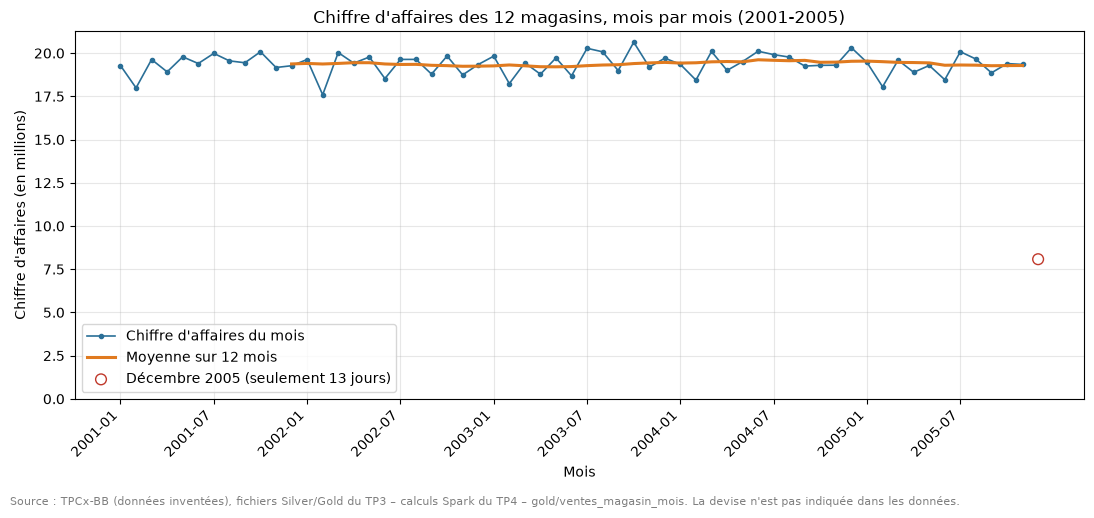

In [17]:
fig, ax = plt.subplots(figsize=(11, 5))
x = range(len(pdf_mois))
c = pdf_mois[~pdf_mois["partiel"]]
p = pdf_mois[pdf_mois["partiel"]]
ax.plot(c.index, c["ca"] / 1e6, marker="o", markersize=3, linewidth=1.2, color="#2a6f97", label="Chiffre d'affaires du mois")
ax.plot(c.index, c["moyenne_mobile_12m"] / 1e6, linewidth=2.2, color="#e07a1f", label="Moyenne sur 12 mois")
ax.scatter(p.index, p["ca"] / 1e6, marker="o", facecolors="none", edgecolors="#c0392b", s=60,
           label="Décembre 2005 (seulement 13 jours)", zorder=3)
ticks = [i for i, m in enumerate(pdf_mois["mois"]) if m in (1, 7)]
ax.set_xticks(ticks)
ax.set_xticklabels(pdf_mois.loc[ticks, "mois_txt"], rotation=45, ha="right")
ax.set_ylim(0, None)
ax.set_title("Chiffre d'affaires des 12 magasins, mois par mois (2001-2005)")
ax.set_xlabel("Mois")
ax.set_ylabel("Chiffre d'affaires (en millions)")
ax.grid(True, alpha=0.3)
ax.legend(loc="lower left")
fig.text(0.01, -0.02, SOURCE_GRAPHIQUE + " – gold/ventes_magasin_mois. La devise n'est pas indiquée dans les données.",
         fontsize=8, color="gray")
plt.tight_layout()
plt.savefig(VISUALISATIONS / "evolution_ventes_mensuelles.png", dpi=150, bbox_inches="tight")
plt.show()

**Ce que montre le graphique** : le chiffre d'affaires des 12 magasins, mois par mois (en bleu), et sa moyenne sur 12 mois (en orange).

**Ce que je vois** : le chiffre d'affaires est **très stable** : 19,4 millions par mois en moyenne, entre 17,6 M (février 2002)
et 20,6 M (octobre 2003). Les mois varient très peu (3 % autour de la moyenne). La ligne orange est presque plate :
d'une année à l'autre, sur la même période, on reste entre −1,5 % et +1,1 % (voir K7). Les petites différences suivent
surtout le **nombre de jours** du mois : février (28 jours) est toujours le plus bas (18,1 M en moyenne).

**Ce que ça peut vouloir dire** : les ventes n'augmentent pas, et il n'y a pas de saison (pas de pic à Noël).
Dans un vrai magasin, on verrait un pic en novembre-décembre. Ici, c'est le programme TPCx-BB qui répartit les ventes
de façon presque égale dans le temps.

**Limites** : données inventées ; décembre 2005 incomplet (le deuxième lot de données n'a pas été traité) ;
ventes en magasin seulement (pas le web) ; les retours ne sont pas enlevés.

## 6. Analyse 2 – Quels magasins marchent le mieux ? (Q5)

| | |
|---|---|
| **Question** | Quels magasins vendent le plus (chiffre d'affaires, tickets, panier moyen, chiffre d'affaires par employé) ? (Q5 du TP1) |
| **Qui la pose** | Les responsables de magasin, pour fixer des objectifs à chaque magasin |
| **Données** | `silver/sales` (ventes, tickets) + `silver/stores` (nom, nombre d'employés) – calculé dans la partie 3 |
| **Méthode** | K1, K2, K3 et K11 pour chaque magasin, puis l'écart de chaque magasin par rapport à la moyenne |
| **Pourquoi pas le Gold ?** | Additionner les tickets de chaque mois serait faux si un ticket était à cheval sur deux mois. Recompter dans le Silver est plus sûr. |

In [18]:
pdf_mag = pdf_magasins.copy()
for col in ["K1_ca_net", "K3_panier_moyen", "K11_ca_par_employe"]:
    pdf_mag[col] = pdf_mag[col].astype(float)
moy = pdf_mag["K1_ca_net"].mean()
pdf_mag["ecart_moyenne_pct"] = ((pdf_mag["K1_ca_net"] / moy - 1) * 100).round(2)
pdf_mag["rang_ca"] = pdf_mag["K1_ca_net"].rank(ascending=False).astype(int)
pdf_mag["rang_ca_par_employe"] = pdf_mag["K11_ca_par_employe"].rank(ascending=False).astype(int)
pdf_mag = pdf_mag.sort_values("K1_ca_net", ascending=False)
pdf_mag.to_csv(OUTPUTS / "ventes_par_magasin.csv", index=False)

print(f"Écart entre le 1er et le dernier magasin : "
      f"{(pdf_mag['K1_ca_net'].max() / pdf_mag['K1_ca_net'].min() - 1) * 100:.1f} %")
pdf_mag[["s_store_name", "s_state", "K1_ca_net", "ecart_moyenne_pct", "K2_nb_transactions",
         "K3_panier_moyen", "s_number_employees", "K11_ca_par_employe", "rang_ca", "rang_ca_par_employe"]]

Écart entre le 1er et le dernier magasin : 5.2 %


,s_store_name,s_state,K1_ca_net,ecart_moyenne_pct,K2_nb_transactions,K3_panier_moyen,s_number_employees,K11_ca_par_employe,rang_ca,rang_ca_par_employe
0,Buffalo,KS,98 950 137.76,3.20,7645,12 943.12,225,439 778.39,1,3
1,Elmwood,KY,96 770 105.59,0.93,7462,12 968.39,254,380 984.67,2,9
2,Germantown,WV,96 748 356.68,0.91,7435,13 012.56,213,454 217.64,3,1
3,Forest,CO,96 727 851.94,0.89,7456,12 973.16,217,445 750.47,4,2
4,Williamstown,TX,96 578 622.89,0.73,7414,13 026.52,298,324 089.34,5,12
5,Pioneer,TX,96 063 990.59,0.19,7396,12 988.64,221,434 678.69,6,5
6,Hillside,TN,95 929 844.66,0.05,7422,12 925.07,244,393 155.10,7,8
7,Bedford,KY,95 607 843.48,-0.28,7449,12 834.99,221,432 614.68,8,6
8,Bloomfield,IN,94 751 173.08,-1.17,7284,13 008.12,225,421 116.32,9,7
9,Avalon,TN,94 263 977.55,-1.68,7409,12 722.90,254,371 118.02,10,10


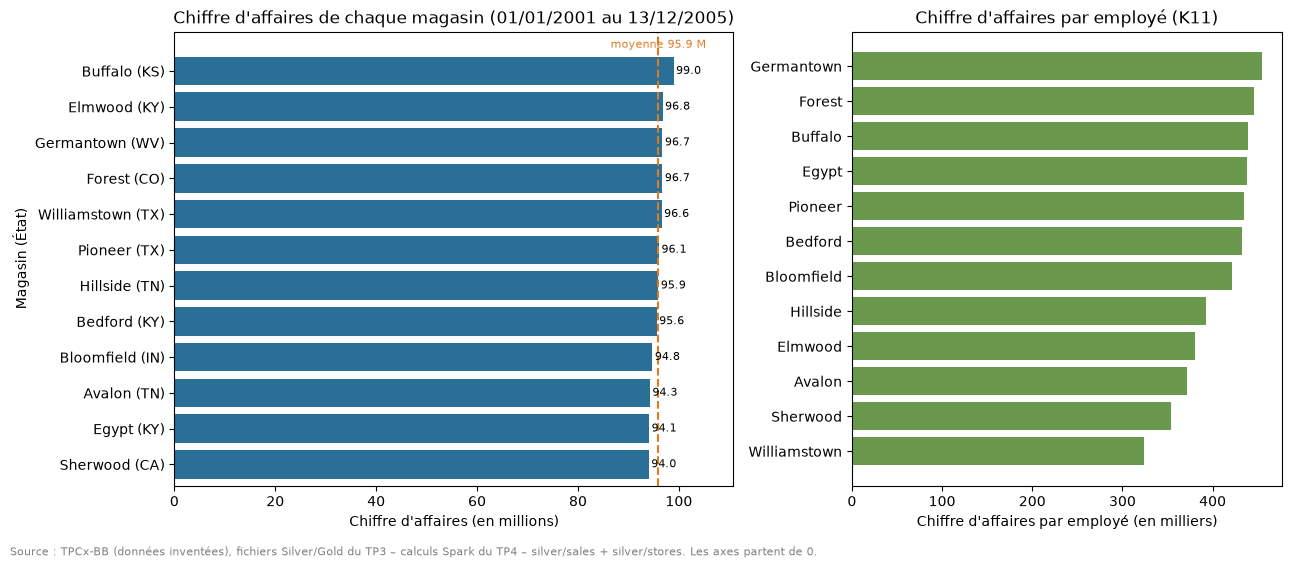

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})

d = pdf_mag.sort_values("K1_ca_net")
etiquettes = d["s_store_name"] + " (" + d["s_state"] + ")"
ax1.barh(etiquettes, d["K1_ca_net"] / 1e6, color="#2a6f97")
ax1.axvline(moy / 1e6, color="#e07a1f", linestyle="--", linewidth=1.5)
ax1.text(moy / 1e6, len(d) - 0.35, f"moyenne {moy/1e6:.1f} M", color="#e07a1f", ha="center", fontsize=8)
ax1.set_ylim(-0.6, len(d) + 0.1)
for y, v in enumerate(d["K1_ca_net"] / 1e6):
    ax1.text(v + 0.5, y, f"{v:.1f}", va="center", fontsize=8)
ax1.set_xlim(0, d["K1_ca_net"].max() / 1e6 * 1.12)
ax1.set_title("Chiffre d'affaires de chaque magasin (01/01/2001 au 13/12/2005)")
ax1.set_xlabel("Chiffre d'affaires (en millions)")
ax1.set_ylabel("Magasin (État)")

d2 = pdf_mag.sort_values("K11_ca_par_employe")
ax2.barh(d2["s_store_name"], d2["K11_ca_par_employe"] / 1e3, color="#6a994e")
ax2.set_title("Chiffre d'affaires par employé (K11)")
ax2.set_xlabel("Chiffre d'affaires par employé (en milliers)")
ax2.set_xlim(0, None)

fig.text(0.01, -0.02, SOURCE_GRAPHIQUE + " – silver/sales + silver/stores. Les axes partent de 0.",
         fontsize=8, color="gray")
plt.tight_layout()
plt.savefig(VISUALISATIONS / "ventes_par_magasin.png", dpi=150, bbox_inches="tight")
plt.show()

**Ce que montre le graphique** : à gauche, le chiffre d'affaires total de chaque magasin. À droite, le chiffre d'affaires
divisé par le nombre d'employés. Les axes partent de 0 pour ne pas grossir les écarts.

**Ce que je vois** : les 12 magasins vendent **presque autant** : de 94,0 M (Sherwood) à 99,0 M (Buffalo), pour une
moyenne de 95,9 M. Il n'y a que 5,2 % d'écart entre le premier et le dernier. Le panier moyen bouge encore moins (12 700 à 13 000).
Par contre, le classement **change beaucoup** quand on divise par le nombre d'employés : Williamstown est 5ᵉ en chiffre
d'affaires, mais il a le plus d'employés (298), donc il devient **dernier**. Germantown (213 employés, le moins) passe **premier**.

**Ce que ça peut vouloir dire** : avec ces données, le chiffre d'affaires seul ne permet pas de dire quel magasin est « le meilleur ».
Le chiffre d'affaires par employé montre plus de différences, mais il dépend surtout du nombre d'employés,
et on ne connaît qu'**un seul nombre d'employés pour les 5 ans**.

**Limites** : données inventées (ventes réparties presque au hasard entre magasins) ; les surfaces sont fausses
(plusieurs millions de m²), donc pas de chiffre d'affaires par m² ; pas de coûts, donc on ne sait pas qui gagne de l'argent ;
un magasin qui vend plus n'est pas forcément mieux géré (taille, ville, clients…).

## 7. Analyse 3 (bonus) – Quelles catégories vendent le plus ? (Q3)

Données : `gold/ventes_categorie_annee`, seulement les années complètes 2001 à 2004 (2005 est incomplète).

In [20]:
ventes_cat = (gold_cat.filter(F.col("annee") <= 2004)
    .groupBy("categorie")
    .agg(F.sum("ca").alias("ca"), F.sum("quantite").alias("quantite"))
    .orderBy(F.desc("ca")))
pdf_cat = ventes_cat.toPandas()        # une dizaine de lignes
pdf_cat["ca"] = pdf_cat["ca"].astype(float)
pdf_cat["part_ca_pct"] = (pdf_cat["ca"] / pdf_cat["ca"].sum() * 100).round(2)
pdf_cat["part_cumulee_pct"] = pdf_cat["part_ca_pct"].cumsum().round(2)
pdf_cat.to_csv(OUTPUTS / "ventes_par_categorie.csv", index=False)

# Est-ce que la part de chaque catégorie change d'une année à l'autre ?
stab = (gold_cat.filter(F.col("annee") <= 2004).groupBy("categorie")
        .agg(F.min("part_ca_pct").alias("part_min"), F.max("part_ca_pct").alias("part_max"))
        .toPandas())
pdf_cat.merge(stab, on="categorie")

,categorie,ca,quantite,part_ca_pct,part_cumulee_pct,part_min,part_max
0,Music,421 255 749.81,12354032,45.23,45.23,45.05,45.43
1,Books,248 183 834.32,7293360,26.65,71.88,26.43,26.77
2,Movies & TV,60 835 794.91,1777914,6.53,78.41,6.41,6.63
3,Clothing & Accessories,45 733 997.02,1321035,4.91,83.32,4.82,4.99
4,Electronics,44 888 929.48,1316191,4.82,88.14,4.72,4.89
5,Home & Kitchen,33 358 520.34,992609,3.58,91.72,3.53,3.62
6,Sports & Outdoors,33 077 603.08,980342,3.55,95.27,3.48,3.59
7,Toys & Games,22 289 388.44,660617,2.39,97.66,2.34,2.47
8,Tools & Home Improvement,21 742 228.17,650868,2.33,99.99,2.31,2.39


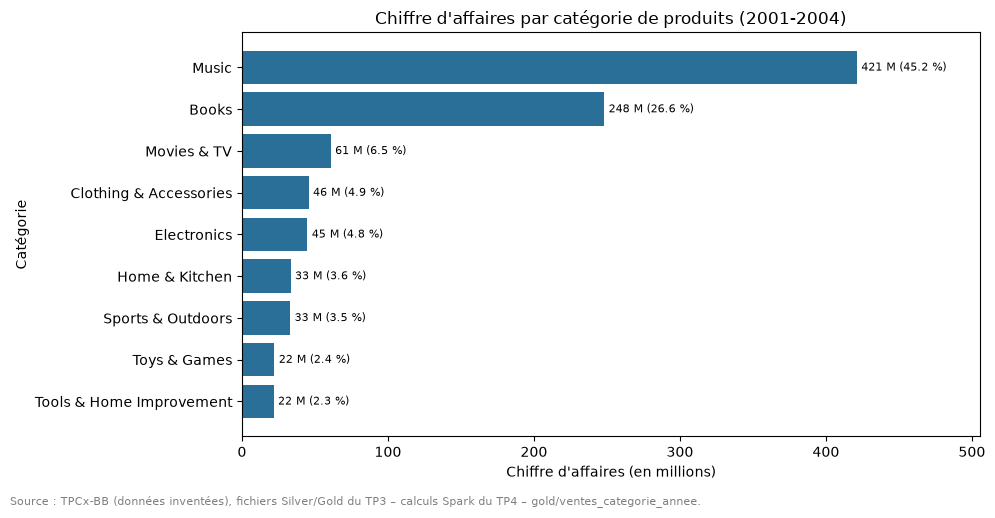

In [21]:
fig, ax = plt.subplots(figsize=(10, 5))
d = pdf_cat.sort_values("ca")
ax.barh(d["categorie"].fillna("(vide)"), d["ca"] / 1e6, color="#2a6f97")
for y, (v, pct) in enumerate(zip(d["ca"] / 1e6, d["part_ca_pct"])):
    ax.text(v + 3, y, f"{v:.0f} M ({pct:.1f} %)", va="center", fontsize=8)
ax.set_xlim(0, d["ca"].max() / 1e6 * 1.2)
ax.set_title("Chiffre d'affaires par catégorie de produits (2001-2004)")
ax.set_xlabel("Chiffre d'affaires (en millions)")
ax.set_ylabel("Catégorie")
fig.text(0.01, -0.02, SOURCE_GRAPHIQUE + " – gold/ventes_categorie_annee.", fontsize=8, color="gray")
plt.tight_layout()
plt.savefig(VISUALISATIONS / "ventes_par_categorie.png", dpi=150, bbox_inches="tight")
plt.show()

**Ce que je vois** : il y a 9 catégories, mais deux font presque tout : **Music** (45,2 %) et **Books** (26,7 %), soit 71,9 % à elles deux.
Ces parts sont presque les mêmes chaque année (moins de 0,4 point d'écart).

**Ce que ça peut vouloir dire** : ça vient peut-être juste du **nombre de produits** dans chaque catégorie, plutôt que des goûts
des clients (à vérifier avec `silver/products`). **Limite** : sans marge fiable, une catégorie qui vend beaucoup
ne rapporte pas forcément beaucoup.

## 8. Répartition des montants des tickets (histogramme)

Un **histogramme** montre combien de tickets il y a dans chaque tranche de prix (ici, des tranches de 2 000).

Le TP demande de faire les calculs avec Spark avant de passer à Pandas. Je fais donc **ranger les tickets par tranche par Spark** :
seules les 33 tranches passent dans Pandas, et pas les 89 100 tickets.

In [22]:
LARGEUR = 2000
distribution = (tickets
    .withColumn("classe", (F.floor(F.col("montant_ticket") / LARGEUR) * LARGEUR).cast("int"))
    .groupBy("classe").count().orderBy("classe"))
pdf_dist = distribution.toPandas()
pdf_dist.to_csv(OUTPUTS / "distribution_montant_tickets.csv", index=False)

q = tickets.select(F.percentile_approx("montant_ticket", [0.25, 0.5, 0.75, 0.95]).alias("q")).first()["q"]
moyenne = float(tickets.agg(F.avg("montant_ticket")).first()[0])
print(f"{len(pdf_dist)} classes ; Q1={float(q[0]):.0f}  médiane={float(q[1]):.0f}  Q3={float(q[2]):.0f}  "
      f"P95={float(q[3]):.0f}  moyenne={moyenne:.0f}")

33 classes ; Q1=5571  médiane=11641  Q3=18787  P95=29599  moyenne=12913


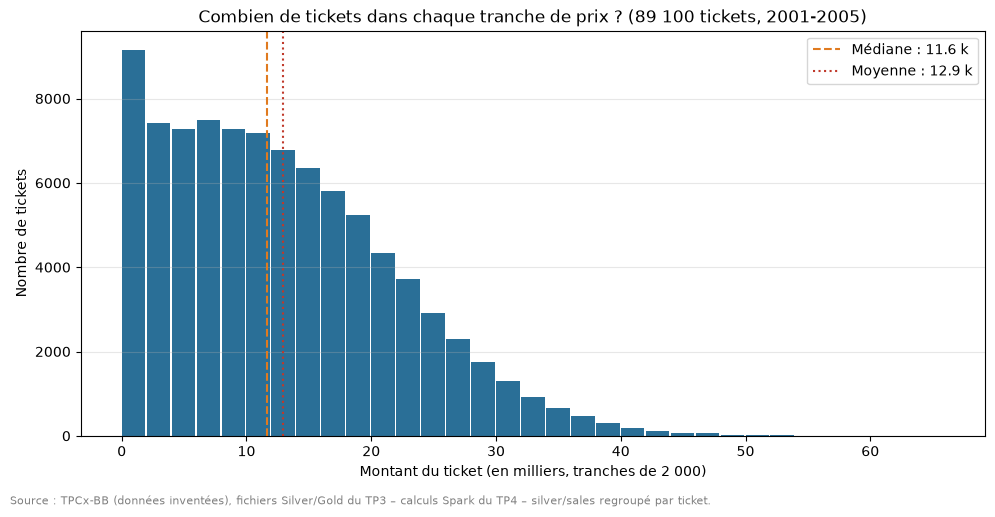

In [23]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(pdf_dist["classe"] / 1e3, pdf_dist["count"], width=LARGEUR / 1e3 * 0.95, align="edge", color="#2a6f97")
ax.axvline(float(q[1]) / 1e3, color="#e07a1f", linestyle="--", label=f"Médiane : {float(q[1])/1e3:.1f} k")
ax.axvline(moyenne / 1e3, color="#c0392b", linestyle=":", label=f"Moyenne : {moyenne/1e3:.1f} k")
ax.set_title("Combien de tickets dans chaque tranche de prix ? (89 100 tickets, 2001-2005)")
ax.set_xlabel("Montant du ticket (en milliers, tranches de 2 000)")
ax.set_ylabel("Nombre de tickets")
ax.legend()
ax.grid(True, axis="y", alpha=0.3)
fig.text(0.01, -0.02, SOURCE_GRAPHIQUE + " – silver/sales regroupé par ticket.", fontsize=8, color="gray")
plt.tight_layout()
plt.savefig(VISUALISATIONS / "distribution_montant_tickets.png", dpi=150, bbox_inches="tight")
plt.show()

**Ce que je vois** : il y a beaucoup de petits tickets et quelques très gros (jusqu'à 64 800). Ces gros tickets tirent la moyenne
(12 913) au-dessus de la médiane (11 641). La moitié des tickets est entre 5 600 et 18 800. La première tranche (0 à 2 000)
est plus haute que les suivantes : ce sont les tickets avec très peu de produits.

Le panier moyen (12 913) donne donc une image un peu trop haute : la médiane décrit mieux un ticket « normal ».
Les montants ne sont pas réalistes pour un vrai magasin (environ 50 articles par ligne, à cause du programme qui a inventé les données).

## 9. Conclusions, limites et conseils (étape 6)

Le texte complet est dans `docs/interpretation.md`. En résumé :

| # | Ce que je vois | Ce que ça peut vouloir dire | Limite | Mon conseil |
|---|---|---|---|---|
| C1 | Chiffre d'affaires stable (19,4 M par mois, 3 % de variation), entre −1,5 % et +1,1 % par an, pas de pic à Noël | Pas de croissance et pas de saison | Données inventées ; décembre 2005 incomplet | Fixer les objectifs avec la moyenne sur 12 mois, pas avec un seul mois ; traiter le deuxième lot de données pour compléter 2005 |
| C2 | Les 12 magasins vendent presque autant (5 % d'écart), mais le classement change par employé (Williamstown passe de 5ᵉ à 12ᵉ) | Le chiffre d'affaires seul ne suffit pas pour comparer les magasins | Nombre d'employés fixe sur 5 ans ; surfaces fausses ; pas de coûts | Comparer avec des chiffres par employé ou par ticket, et demander les coûts (K13) |
| C3 | Music + Books = 72 % des ventes, toujours pareil | Ça vient peut-être du nombre de produits | Pas de marge fiable | Compter les produits par catégorie avant de changer les rayons |
| C4 | Panier moyen 12 913, médiane 11 641 | Les gros tickets tirent la moyenne vers le haut | Montants pas réalistes | Montrer aussi la médiane |

**Quand deux choses vont ensemble, ça ne veut pas dire que l'une cause l'autre.** Et ces données ne parlent pas d'un vrai magasin.

In [24]:
spark.stop()
print("Fichiers produits :")
for p in sorted(list(OUTPUTS.glob("*")) + list(VISUALISATIONS.glob("*"))):
    print(" ", p.relative_to(RACINE), f"({p.stat().st_size // 1024} Ko)")

Fichiers produits :
  graphiques/distribution_montant_tickets.png (62 Ko)
  graphiques/evolution_ventes_mensuelles.png (107 Ko)
  graphiques/ventes_par_categorie.png (84 Ko)
  graphiques/ventes_par_magasin.png (135 Ko)
  resultats/ca_annuel.csv (0 Ko)
  resultats/distribution_montant_tickets.csv (0 Ko)
  resultats/kpi.csv (0 Ko)
  resultats/kpi_par_magasin.csv (0 Ko)
  resultats/statistiques.csv (0 Ko)
  resultats/ventes_par_categorie.csv (0 Ko)
  resultats/ventes_par_magasin.csv (1 Ko)
  resultats/ventes_par_mois.csv (3 Ko)
